
# 🌳 Decision Tree & Random Forest

# 1. Decision Tree

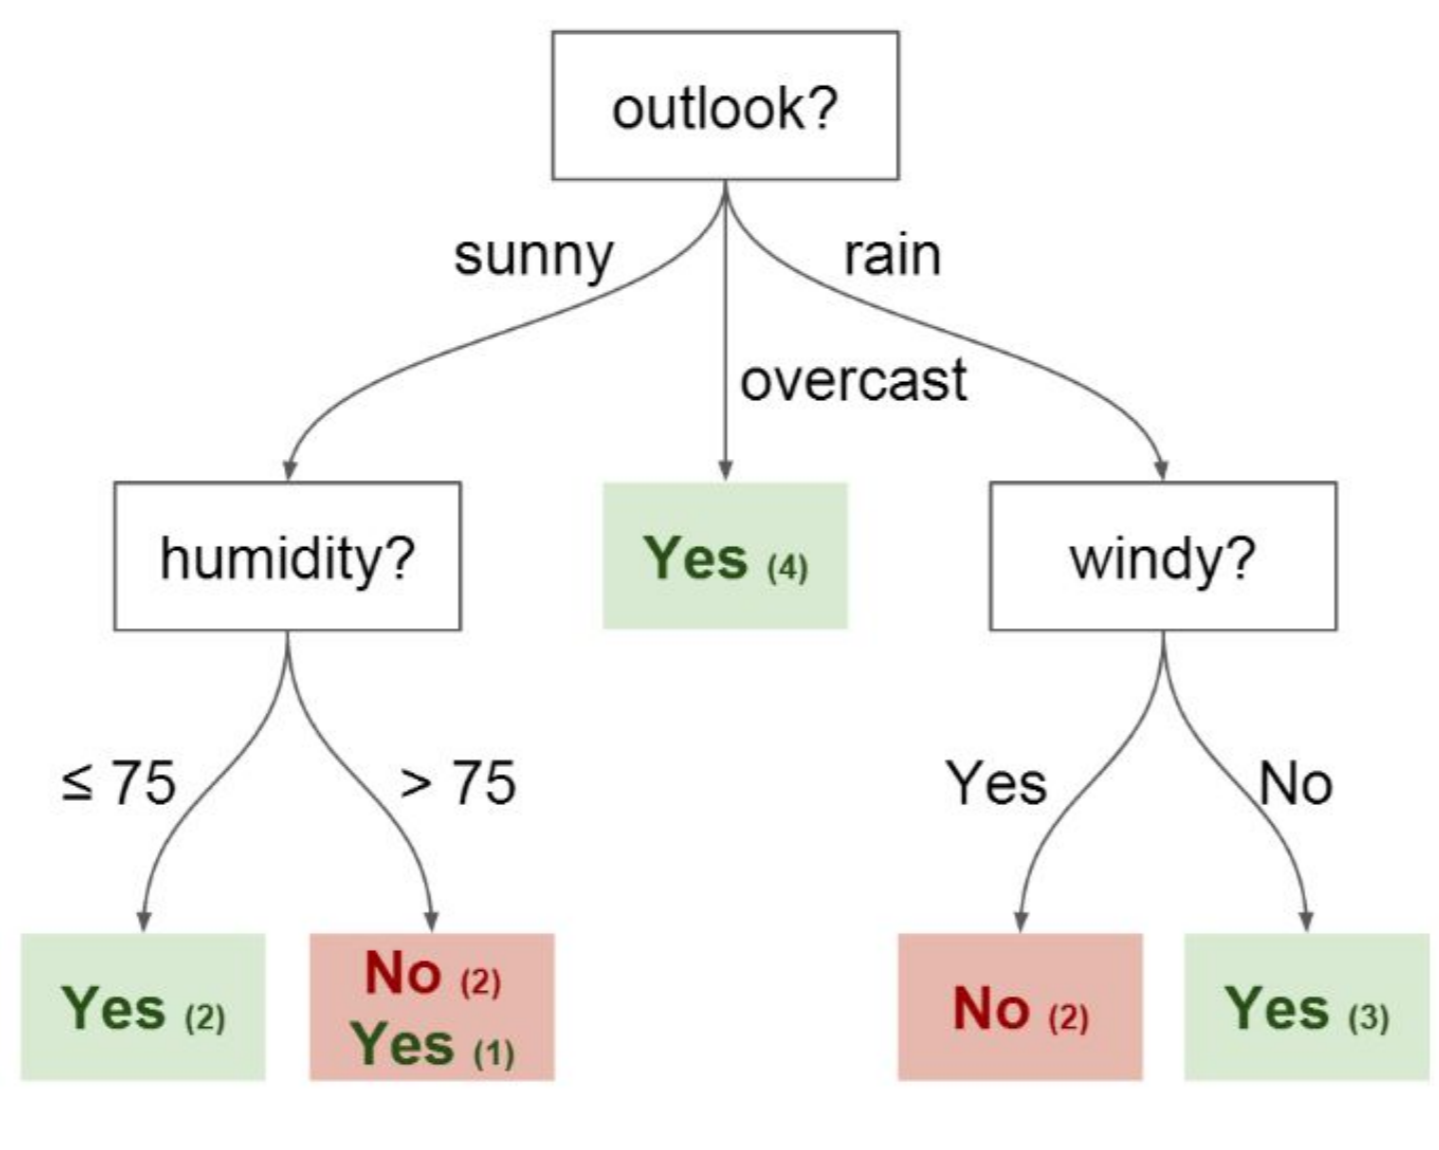

Decision Trees are an important type of algorithm for predictive modeling machine learning.

The classical decision tree algorithms have been around for decades and modern variations like random forest are among the most powerful techniques available.

Classification and Regression Trees or `CART` for short is a term introduced by `Leo Breiman` to refer to Decision Tree algorithms that can be used for classification or regression predictive modeling problems.

Classically, this algorithm is referred to as “`decision trees`”, but on some platforms like R they are referred to by the more modern term CART.

The `CART` algorithm provides a foundation for important algorithms like `bagged decision trees`, `random forest` and `boosted decision trees`.

### CART Model Representation
The representation for the CART model is a binary tree.

This is your binary tree from algorithms and data structures, nothing too fancy. Each root node represents a single input variable (x) and a split point on that variable (assuming the variable is numeric).

The leaf nodes of the tree contain an output variable (y) which is used to make a prediction.

Given a new input, the tree is traversed by evaluating the specific input started at the root node of the tree.

#### Some **advantages** of decision trees are:
* Simple to understand and to interpret. Trees can be visualised.
* Requires little data preparation. 
* Able to handle both numerical and categorical data.
* Possible to validate a model using statistical tests. 
* Performs well even if its assumptions are somewhat violated by the true model from which the data were generated.

#### The **disadvantages** of decision trees include:
* Overfitting. Mechanisms such as pruning (not currently supported), setting the minimum number of samples required at a leaf node or setting the maximum depth of the tree are necessary to avoid this problem.
* Decision trees can be unstable. Mitigant: Use decision trees within an ensemble.
* Cannot guarantee to return the globally optimal decision tree. Mitigant: Training multiple trees in an ensemble learner
* Decision tree learners create biased trees if some classes dominate. Recommendation: Balance the dataset prior to fitting

# 2. Random Forest
Random Forest is one of the most popular and most powerful machine learning algorithms. It is a type of ensemble machine learning algorithm called Bootstrap Aggregation or bagging.

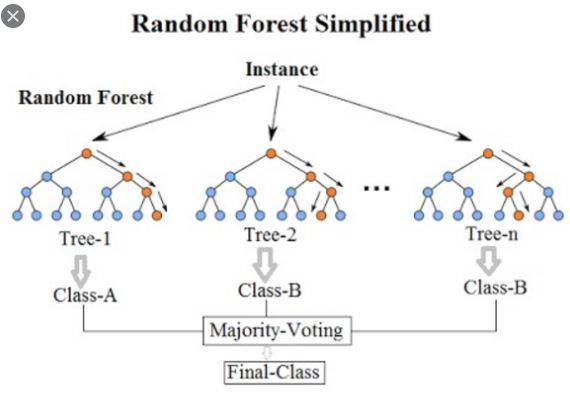

To improve performance of Decision trees, we can use many trees with a random sample of features chosen as the split.

# 3. Decision Tree & Random Forest Implementation in python

We will use Decision Tree & Random Forest in Predicting the attrition of your valuable employees.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_style("whitegrid")
plt.style.use("fivethirtyeight")

# Using a pre-defined seed makes results be the same every time we run the code. The author decided to use the seed 42.
random_state = 42
models = {}   # every trained model, collected for the final comparison

In [2]:
from matplotlib import colormaps
from matplotlib.colors import to_hex

# The variable and functions below allow the correct conversion to LaTeX tables when exporting to PDF with nbconvert.
def correctness_html(value):
    return {
        'Yes': 'color: green; font-weight: bold;',
        'No': 'color: red; font-weight: bold;',
    }.get(value, '')


def _blues(value):
    """Map a value in [0, 1] to a 'Blues' hex colour and whether it is dark."""
    r, g, b, _ = colormaps["Blues"](float(value))
    return to_hex((r, g, b))[1:].upper(), (0.299 * r + 0.587 * g + 0.114 * b) < 0.5


def gradient_html(value):
    hex_code, dark = _blues(value)
    return f"background-color: #{hex_code}; color: {'white' if dark else 'black'};"


def gradient_latex(value):
    hex_code, dark = _blues(value)
    return f"cellcolor:[HTML]{{{hex_code}}}; color:{{{'white' if dark else 'black'}}};"

def correctness_latex(value):
    return {
        'Yes': 'color:{green}; bfseries:;',
        'No': 'color:{red}; bfseries:;',
    }.get(value, '')


def display_table(
        df,
        formats=None,
        latex_formats=None,
        html_style=None,
        latex_style=None,
        style_columns=None,
        hide_index=True,
        fit_to_page=False,
        na_rep=None,
        multipage=None,
):
    r"""
    Display a DataFrame as HTML and LaTeX for notebook viewing and PDF export.

    Formats values without modifying the DataFrame. The LaTeX version includes
    alternating row shading, bold headers, and escaped row and column labels.

    Parameters
    ----------
    df : pandas.DataFrame
        Table to display.
    formats : dict, optional
        Column names mapped to format strings or formatting functions.
        Used for both outputs unless overridden by latex_formats.
    latex_formats : dict, optional
        Formatting overrides for LaTeX output. Formatters that generate special
        characters must escape them, for example '%' as r'\%'.
    html_style : callable, optional
        Function receiving a cell value and returning a CSS style string.
        Return an empty string to leave the cell unchanged.
    latex_style : callable, optional
        Function receiving a cell value and returning a pandas LaTeX style
        string, such as 'color:{green}; bfseries:;'.
    style_columns : list of str, optional
        Columns to which the styling functions apply. If None, apply them
        to all data cells. Callbacks receive original, unformatted values.
    hide_index : bool, default True
        Hide row indexes in both output formats.
    fit_to_page : bool, default False
        Shrink the LaTeX table if it exceeds the PDF text width.
        Does not affect the HTML display.
    na_rep : str or None, default None
        Text displayed for missing values. If None, use the default rendering
        without a custom replacement. Does not modify the underlying data.

    multipage : bool or None, default None
        Use a LaTeX longtable with repeated headers and page breaks.
        None enables this unless fit_to_page=True. Explicitly combining
        multipage=True and fit_to_page=True raises ValueError.

    Returns
    -------
    None
        Displays HTML and LaTeX representations through IPython.display.

    Notes
    -----
    The PDF template must load xcolor and colortbl for LaTeX styling,
    longtable for multipage tables, and adjustbox when fit_to_page=True.
    Rerun and save the cell outputs before exporting without execution.
    """
    if multipage is None:
        multipage = not fit_to_page
    if multipage and fit_to_page:
        raise ValueError('Multipage tables cannot use fit_to_page=True; disable resizing.')

    formats = formats or {}
    pdf_formats = {**formats, **(latex_formats or {})}

    html = df.style.format(formats, na_rep=na_rep, escape='html')

    if hide_index:
        # There is a pandas LaTeX styling bug when the index is hidden.
        latex = (
            df.style
            .format(pdf_formats, na_rep=na_rep, escape='latex')
            .format_index(escape='latex', axis=0)
            .format_index(
                lambda value: r"\textbf{" + _tex(value) + "}",
                axis=1,
            )
        )
    else:
        latex = (
            df.style
            .format(pdf_formats, na_rep=na_rep, escape='latex')
            .format_index(escape='latex', axis=0)
            .format_index(escape='latex', axis=1)
        )

    if hide_index:
        html = html.hide(axis='index')
        latex = latex.hide(axis='index')

    # Apply LaTeX row shading and bold labels.
    def stripe_rows(values):
        return [
            'cellcolor:{gray!10}--rwrap;' if i % 2 == 0 else ''
            for i in range(len(values))
        ]

    def style_index(values):
        return [style + 'bfseries:;' for style in stripe_rows(values)]

    if hide_index:
        # There is a pandas LaTeX styling bug when the index is hidden.
        latex = (
            latex
            .apply(stripe_rows, axis=0)
            .apply_index(style_index, axis=0)
        )
    else:
        latex = (
            latex
            .apply(stripe_rows, axis=0)
            .apply_index(style_index, axis=0)
            .map_index(lambda value: 'bfseries:;', axis=1)
        )

    # Apply caller-supplied styles to selected columns.
    # If style_columns is None, apply to all data cells.
    if html_style is not None:
        html = html.map(html_style, subset=style_columns)

    if latex_style is not None:
        latex = latex.map(latex_style, subset=style_columns)

    latex_output = latex.to_latex(
        environment='longtable' if multipage else None,
    )

    if fit_to_page:
        latex_output = (
                r"\begin{adjustbox}{max width=\linewidth}" "\n"
                + latex_output
                + "\n" r"\end{adjustbox}"
        )

    display({
        'text/html': html.to_html(),
        'text/latex': latex_output,
    }, raw=True)


# display_estimator: show a scikit-learn model as the interactive HTML diagram in the notebook,
# and as an equivalent boxed LaTeX diagram when exporting to PDF with nbconvert
# (nbconvert cannot render the HTML diagram and would otherwise fall back to plain text).
import inspect
from sklearn.base import BaseEstimator
from sklearn.pipeline import Pipeline
from sklearn.utils import estimator_html_repr


def _tex(text):
    """Escape LaTeX special characters."""
    rep = {'\\': r'\textbackslash{}', '&': r'\&', '%': r'\%', '$': r'\$', '#': r'\#',
           '_': r'\_', '{': r'\{', '}': r'\}', '~': r'\textasciitilde{}', '^': r'\textasciicircum{}'}
    return ''.join(rep.get(ch, ch) for ch in str(text))


def _changed_params(est):
    """Parameters that differ from their defaults (nested estimators are drawn as boxes instead)."""
    defaults = inspect.signature(type(est).__init__).parameters
    shown = []
    for name, value in est.get_params(deep=False).items():
        if name == 'steps' or isinstance(value, BaseEstimator):
            continue
        default = defaults[name].default if name in defaults else inspect.Parameter.empty
        try:
            if value is default or value == default:
                continue
        except Exception:  # e.g. arrays, where == is element-wise
            pass
        text = value.__name__ if callable(value) and hasattr(value, '__name__') else repr(value)
        shown.append(f"{name}={text}")
    return shown


def _estimator_latex(est, name=None, depth=0):
    """Nested boxes: one per estimator, pipeline steps joined by arrows."""
    fill = ['gray!12', 'white', 'blue!6'][depth % 3]
    if isinstance(est, str):  # e.g. 'passthrough' / 'drop' pipeline steps
        return r'\fcolorbox{gray}{' + fill + r'}{\texttt{' + _tex(f"{name}: {est}") + '}}'
    title = type(est).__name__ if name is None else f"{name}: {type(est).__name__}"
    rows = [r'\textbf{' + _tex(title) + '}']
    rows += [r'\footnotesize\texttt{' + _tex(p) + '}' for p in _changed_params(est)]
    if isinstance(est, Pipeline):
        children = [_estimator_latex(step, step_name, depth + 1) for step_name, step in est.steps]
        rows.append(r'\begin{tabular}{c}' + r' \\ $\downarrow$ \\ '.join(children) + r'\end{tabular}')
    else:
        nested = [(n, v) for n, v in est.get_params(deep=False).items() if isinstance(v, BaseEstimator)]
        if nested:
            children = [_estimator_latex(v, n, depth + 1) for n, v in nested]
            rows.append(r'\begin{tabular}{c}' + r' \\ '.join(children) + r'\end{tabular}')
    return r'\fcolorbox{gray}{' + fill + r'}{\begin{tabular}{c}' + r' \\ '.join(rows) + r'\end{tabular}}'


def display_estimator(est):
    """Display a scikit-learn estimator for both notebook viewing (HTML) and PDF export (LaTeX)."""
    display({
        'text/html': estimator_html_repr(est),
        'text/latex': r'\begin{center}' + _estimator_latex(est) + r'\end{center}',
        'text/plain': repr(est),
    }, raw=True)

The dataset is found in [IBM HR Analytics Employee Attrition & Performance](https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset)

In [3]:
#df = pd.read_csv("/kaggle/input/ibm-hr-analytics-attrition-dataset/WA_Fn-UseC_-HR-Employee-Attrition.csv")
df = pd.read_csv("./data/week_3_WA_Fn-UseC_-HR-Employee-Attrition.csv")
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


# Exploratory Data Analysis

<Axes: xlabel='Attrition', ylabel='count'>

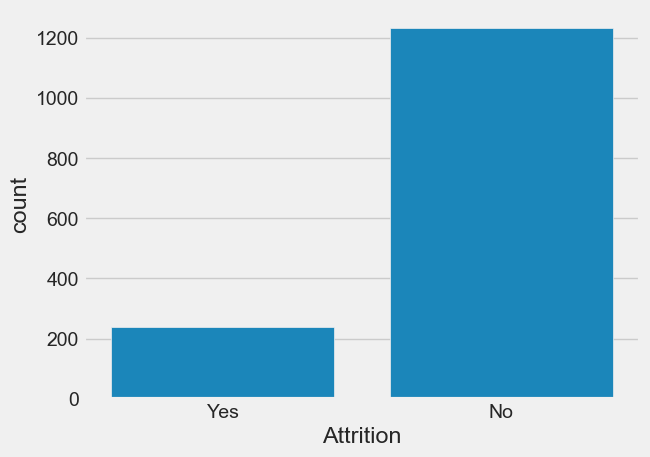

In [4]:
sns.countplot(x='Attrition', data=df)

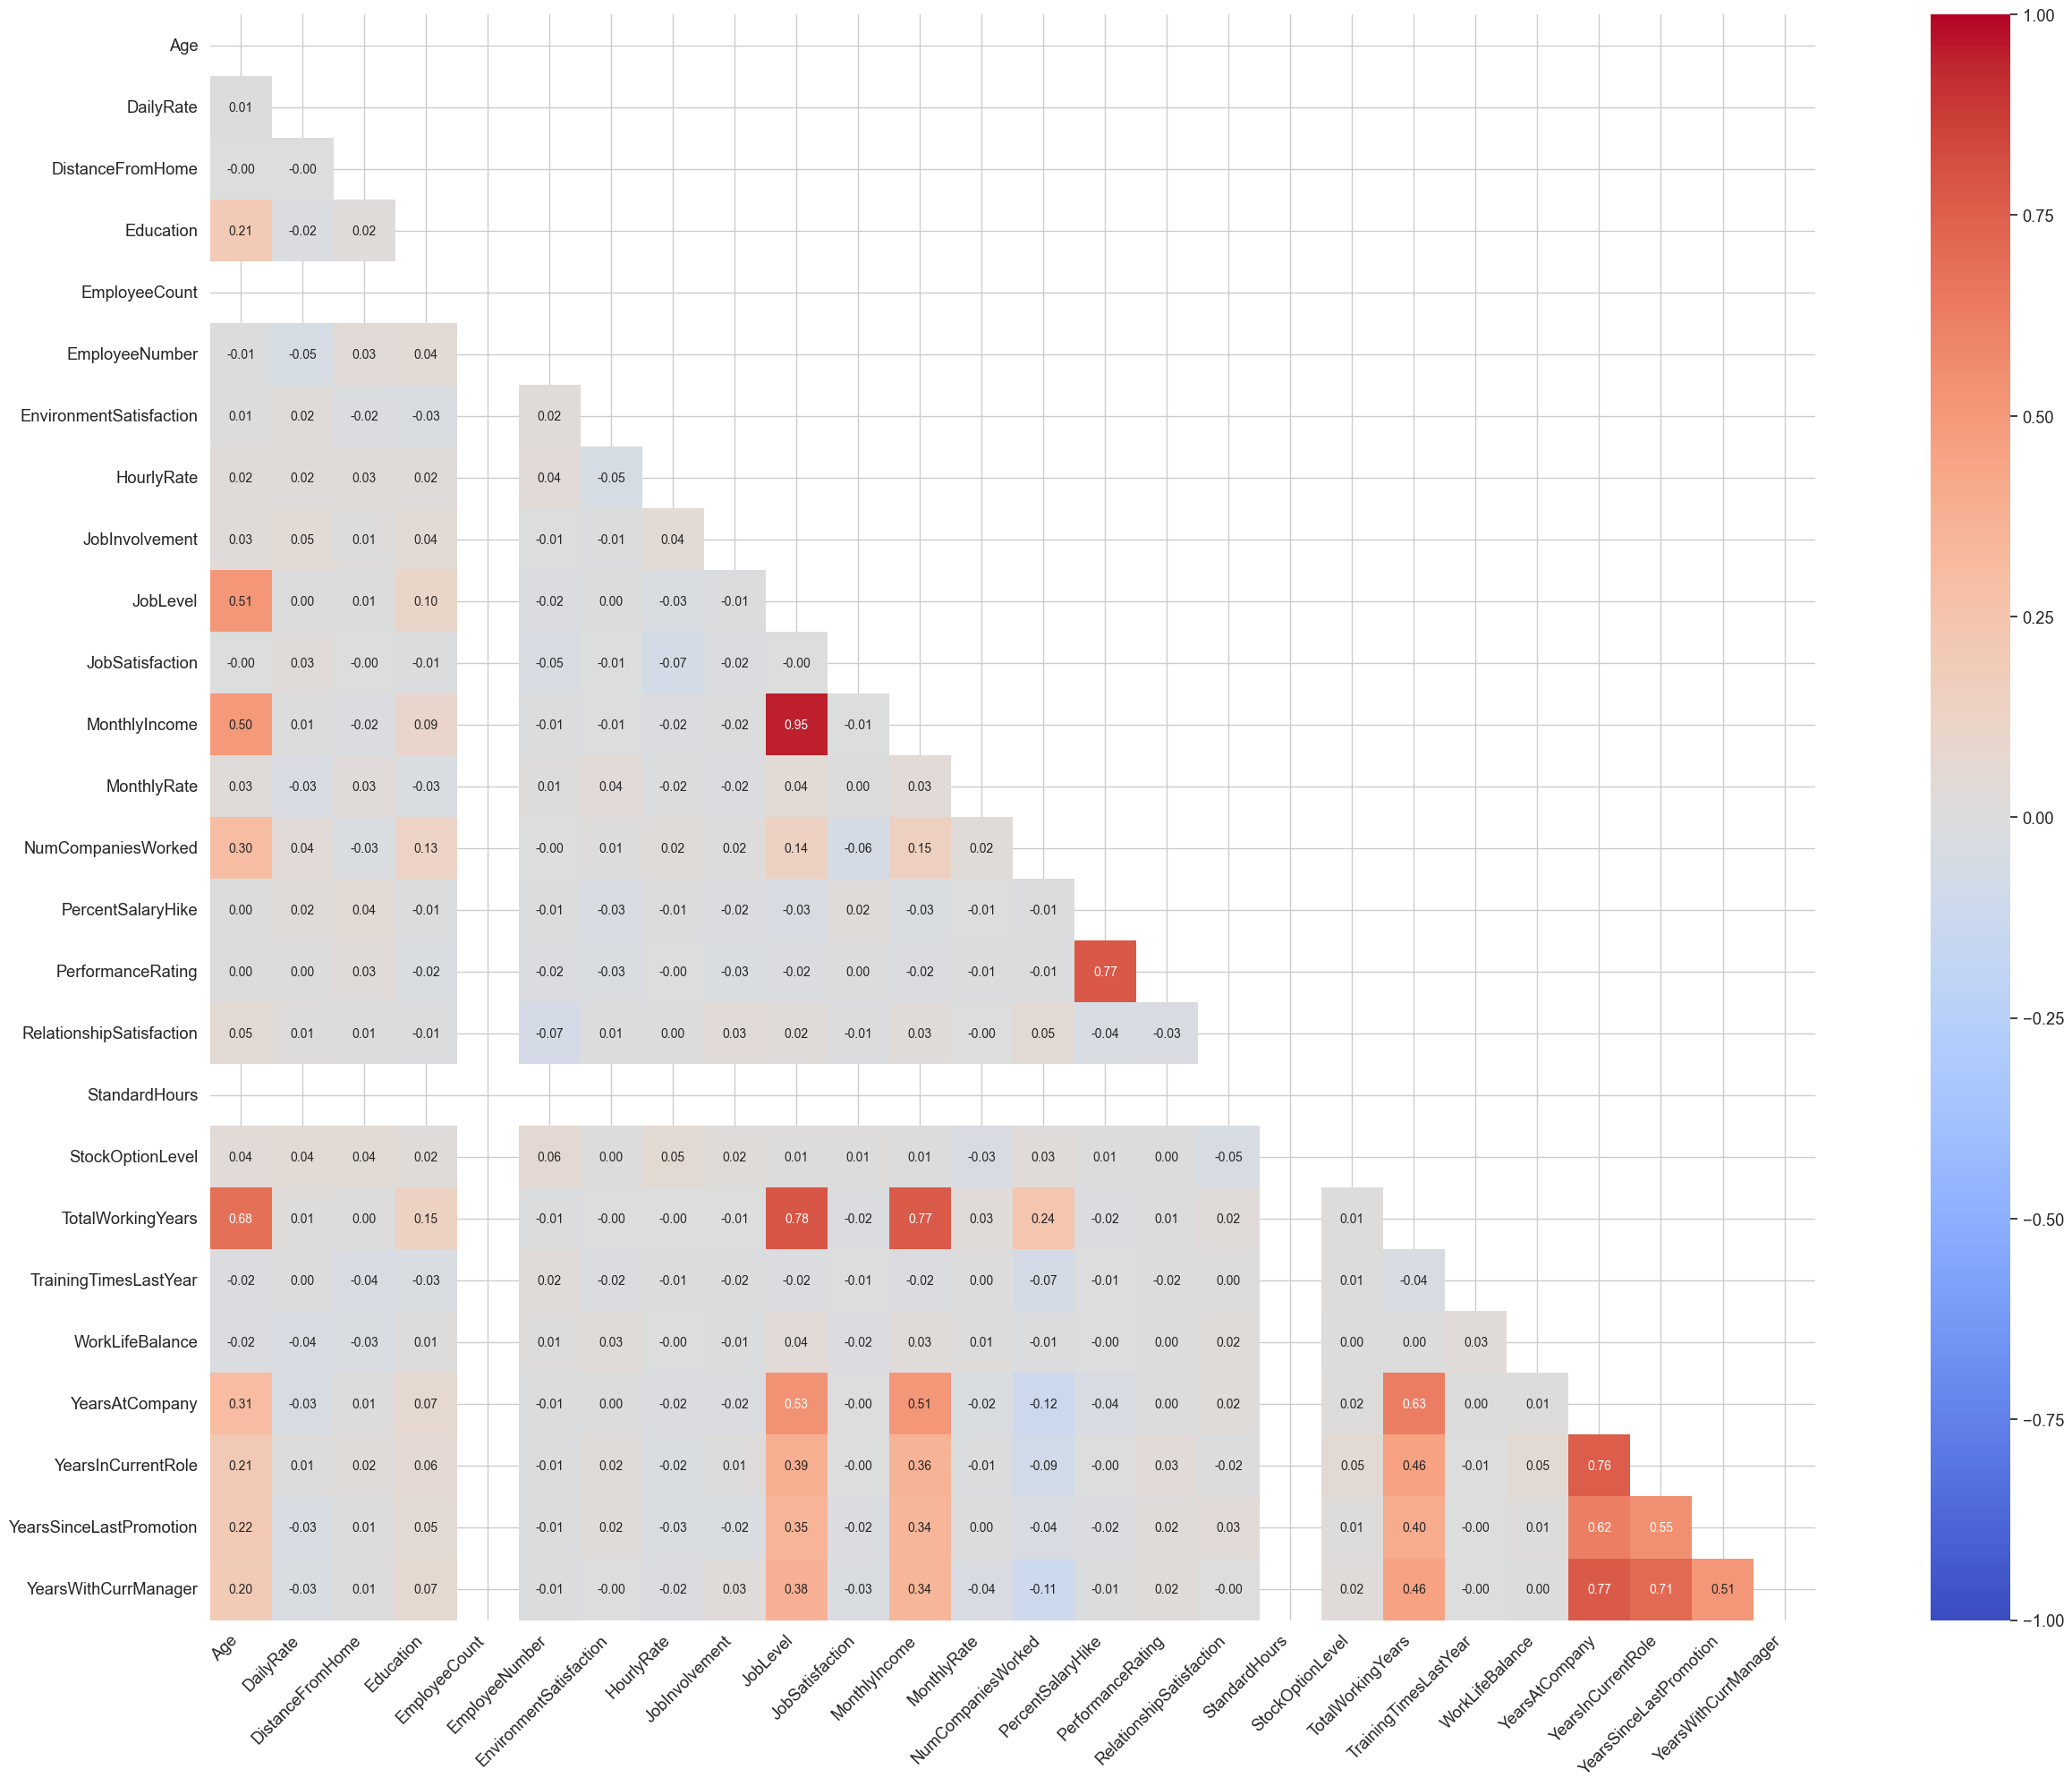

In [5]:
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.2)

# correlation between every pair of numeric columns
# numeric_only=True skips text/category columns, which would otherwise raise an error
cm = df.corr(numeric_only=True)

# optional: hide the upper triangle, because it mirrors the lower one
mask = np.triu(np.ones_like(cm, dtype=bool))

n = len(cm.columns)
f, ax = plt.subplots(figsize=(n * 0.9 + 3, n * 0.7 + 2))   # scale the figure with the number of columns
sns.heatmap(cm, mask=mask, cbar=True, annot=True, square=True, fmt='.2f',
            annot_kws={'size': 10}, cmap='coolwarm', vmin=-1, vmax=1, center=0, ax=ax)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### Removing constant columns

In the correlation heatmap, `EmployeeCount` and `StandardHours` show up as **blank**. Both columns have the **same value in every row** (`EmployeeCount = 1` and `StandardHours = 80`).

Correlation divides by each column's standard deviation:

$$r = \frac{\text{cov}(X, Y)}{\sigma_X \, \sigma_Y}$$

A constant column has $\sigma = 0$, so the result is $0/0 = \text{NaN}$, and seaborn leaves `NaN` cells empty. A column that never changes can't vary together with any other column, so it **carries no information**, either for correlation or for a model.

`Over18` is also constant (always `'Y'`). It didn't appear in the heatmap because it's text, so `numeric_only=True` skipped it.

**Action:** find every column with only one unique value and drop it before computing the correlation and training the model.

In [6]:
df[['EmployeeCount', 'StandardHours']].nunique()   # both return 1

EmployeeCount    1
StandardHours    1
dtype: int64

The code below shows which columns have a higher correlation with `Attrition`. For that, the value of `Attrition` is converted to a binary variable (0 or 1) and then the correlation is computed. The conversion is not done on the original dataframe, so future cells are not affected.

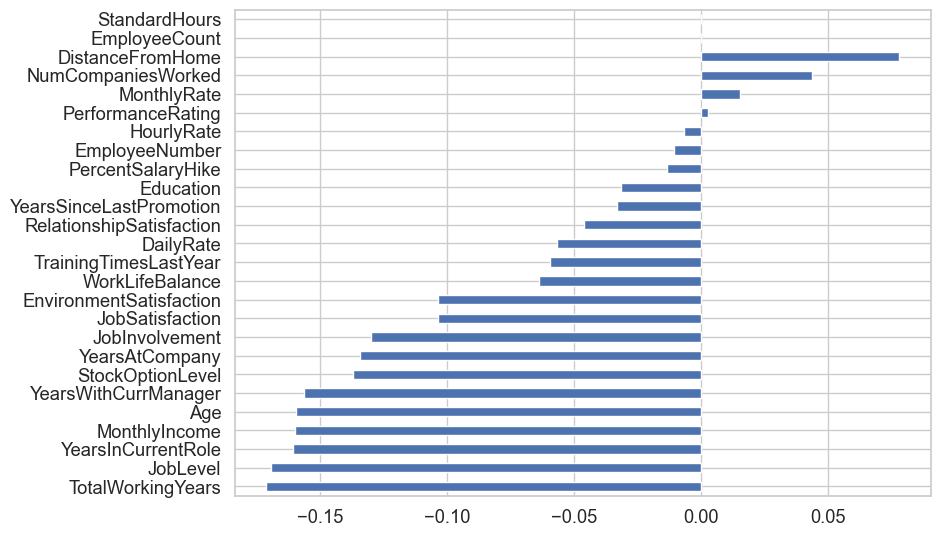

In [7]:
cm = df.assign(Attrition=(df['Attrition'] == 'Yes').astype(int)).corr(numeric_only=True)

cm['Attrition'].drop('Attrition').sort_values().plot.barh(figsize=(8, 6))
plt.show()

### Correlation of each feature with `Attrition`

`Attrition` is stored as text (`'Yes'` / `'No'`), so `df.corr(numeric_only=True)` skips it. To include it, we encode it as `1` (Yes) / `0` (No) **only for this calculation**, using `assign()`. That returns a new DataFrame, so `df` keeps its original values for later processing.

How to read the chart:
- **Positive bar:** higher values of the feature go with employees **leaving**.
- **Negative bar:** higher values go with employees **staying**.
- **Bar length** shows how strong the linear relationship is. Correlation doesn't mean causation.

**Columns missing from the chart:**
- **Text columns** (`OverTime`, `Gender`, `BusinessTravel`, ...) are left out by `numeric_only=True`. They would need encoding to appear.
- **Constant columns** (`EmployeeCount`, `StandardHours`, `Over18`) have the same value in every row. With $\sigma = 0$ their correlation is $\text{NaN}$, so they have nothing to show. `Over18` would be left out anyway because it's text (`'Y'`).

### Dropping uninformative columns

We drop `EmployeeCount`, `EmployeeNumber`, `Over18` and `StandardHours`, because none of them can help predict `Attrition`:

| Column | Reason |
|---|---|
| `EmployeeCount` | **Constant**: always `1`. |
| `StandardHours` | **Constant**: always `80`. |
| `Over18` | **Constant**: always `'Y'`. It's also **redundant with `Age`**, since it could be derived as `Age >= 18`, so it adds nothing `Age` doesn't already tell us. |
| `EmployeeNumber` | **Identifier**: a unique ID for each employee. It varies, but it has no meaning, so a model could only memorise it, which leads to overfitting. |

Constant columns have $\sigma = 0$, so their correlation with any other column is $0/0 = \text{NaN}$ (the blank cells in the heatmap). A feature that never changes can't tell employees apart.

In [8]:
df.drop(['EmployeeCount', 'EmployeeNumber', 'Over18', 'StandardHours'], axis="columns", inplace=True)

categorical_col = []
for column in df.columns:
    if df[column].dtype == object and len(df[column].unique()) <= 50:
        categorical_col.append(column)
        
df['Attrition'] = df.Attrition.astype("category").cat.codes

In [9]:
print(f"Categorical columns: {categorical_col}")

Categorical columns: ['Attrition', 'BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']


# Data Processing

In [10]:
categorical_col.remove('Attrition')

In [11]:
# Transform categorical data into dummies
# categorical_col.remove("Attrition")
# data = pd.get_dummies(df, columns=categorical_col)
# data.info()
from sklearn.preprocessing import LabelEncoder

label = LabelEncoder()
for column in categorical_col:
    df[column] = label.fit_transform(df[column])

In [12]:
from sklearn.model_selection import train_test_split

X = df.drop('Attrition', axis=1)
y = df.Attrition

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=random_state)

# Applying Tree & Random Forest algorithms

In [13]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
from IPython.display import display, Markdown

def print_score(clf, X_train, y_train, X_test, y_test, train=True, ommit_accuracy_bool=True, use_author_stype_output_bool=False):
    if use_author_stype_output_bool:
        if train:
            pred = clf.predict(X_train)
            clf_report = pd.DataFrame(classification_report(y_train, pred, output_dict=True))
            print("Train Result:\n================================================")
            print(f"Accuracy Score: {accuracy_score(y_train, pred) * 100:.2f}%")
            print("_______________________________________________")
            print(f"CLASSIFICATION REPORT:\n{clf_report}")
            print("_______________________________________________")
            print(f"Confusion Matrix: \n {confusion_matrix(y_train, pred)}\n")

        elif train==False:
            pred = clf.predict(X_test)
            clf_report = pd.DataFrame(classification_report(y_test, pred, output_dict=True))
            print("Test Result:\n================================================")
            print(f"Accuracy Score: {accuracy_score(y_test, pred) * 100:.2f}%")
            print("_______________________________________________")
            print(f"CLASSIFICATION REPORT:\n{clf_report}")
            print("_______________________________________________")
            print(f"Confusion Matrix: \n {confusion_matrix(y_test, pred)}\n")
    else:
        X, y = (X_train, y_train) if train else (X_test, y_test)
        split = "Train" if train else "Test"
        pred = clf.predict(X)

        display(Markdown(f"## {split} Results"))
        display(Markdown(f"**Accuracy:** {accuracy_score(y, pred):.2%}"))

        # Accuracy is shown separately, so omit it from the report table.
        report = classification_report(
            y, pred, output_dict=True, zero_division=0
        )

        if ommit_accuracy_bool:
            report.pop("accuracy", None)

        #report_df = pd.DataFrame(report).T.rename_axis("Class / Average")

        report_df = (
            pd.DataFrame(report).T
            .rename_axis("Class / Average")
            .reset_index()          # index -> normal column, so headers sit on one row
        )

        display(Markdown("### Classification Report"))
        '''display(
            report_df.style
            .format({
                "precision": "{:.3f}",
                "recall": "{:.3f}",
                "f1-score": "{:.3f}",
                "support": "{:,.0f}",
            })
            .background_gradient(
                cmap="Blues",
                subset=["precision", "recall", "f1-score"],
                vmin=0,
                vmax=1,
            )
        )'''
        display_table(
            report_df,
            formats={
                "precision": "{:.3f}",
                "recall": "{:.3f}",
                "f1-score": "{:.3f}",
                "support": "{:,.0f}",
            },
            html_style=gradient_html,
            latex_style=gradient_latex,
            style_columns=["precision", "recall", "f1-score"],
        )

        fig, ax = plt.subplots(figsize=(5, 4))
        ConfusionMatrixDisplay.from_predictions(
            y,
            pred,
            cmap="Blues",
            values_format="d",
            colorbar=False,
            ax=ax,
        )
        ax.set_title(f"{split} Confusion Matrix")
        fig.tight_layout()
        plt.show()

## 1. Decision Tree Classifier

**Decision Tree parameters:**
- `criterion`: The function to measure the quality of a split. Supported criteria are "`gini`" for the Gini impurity and "`entropy`" for the information gain.
***
- `splitter`: The strategy used to choose the split at each node. Supported strategies are "`best`" to choose the best split and "`random`" to choose the best random split.
***
- `max_depth`: The maximum depth of the tree. If None, then nodes are expanded until all leaves are pure or until all leaves contain less than `min_samples_split` samples.
***
- `min_samples_split`: The minimum number of samples required to split an internal node.
***
- `min_samples_leaf`: The minimum number of samples required to be at a leaf node. A split point at any depth will only be considered if it leaves at least ``min_samples_leaf`` training samples in each of the left and right branches.  This may have the effect of smoothing the model, especially in regression.
***
- `min_weight_fraction_leaf`: The minimum weighted fraction of the sum total of weights (of all the input samples) required to be at a leaf node. Samples have equal weight when sample_weight is not provided.
***
- `max_features`: The number of features to consider when looking for the best split.
***
- `max_leaf_nodes`: Grow a tree with ``max_leaf_nodes`` in best-first fashion. Best nodes are defined as relative reduction in impurity. If None then unlimited number of leaf nodes.
***
- `min_impurity_decrease`: A node will be split if this split induces a decrease of the impurity greater than or equal to this value.
***
- `min_impurity_split`: Threshold for early stopping in tree growth. A node will split if its impurity is above the threshold, otherwise it is a leaf.

## Train Results

**Accuracy:** 100.00%

### Classification Report

Class / Average,precision,recall,f1-score,support
0,1.000,1.000,1.000,853
1,1.000,1.000,1.000,176
macro avg,1.000,1.000,1.000,"1,029"
weighted avg,1.000,1.000,1.000,"1,029"


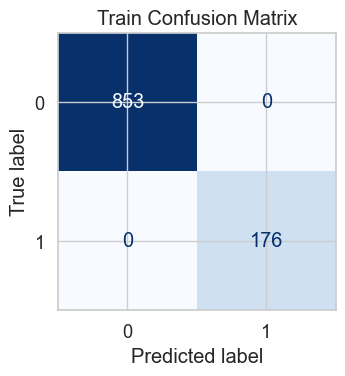

## Test Results

**Accuracy:** 77.78%

### Classification Report

Class / Average,precision,recall,f1-score,support
0,0.887,0.850,0.868,380
1,0.260,0.328,0.290,61
macro avg,0.574,0.589,0.579,441
weighted avg,0.801,0.778,0.788,441


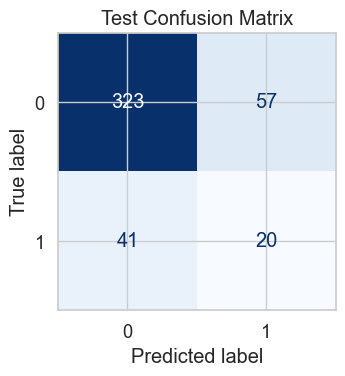

In [14]:
from sklearn.tree import DecisionTreeClassifier

tree_clf = DecisionTreeClassifier(random_state=random_state)
tree_clf.fit(X_train, y_train)

use_author_stype_output_bool=False
print_score(tree_clf, X_train, y_train, X_test, y_test, train=True, use_author_stype_output_bool=use_author_stype_output_bool)
print_score(tree_clf, X_train, y_train, X_test, y_test, train=False, use_author_stype_output_bool=use_author_stype_output_bool)

models["Decision Tree"] = tree_clf

## 2. Decision Tree Classifier Hyperparameter tuning

### Dataset source and GridSearchCV warning

This notebook uses the **IBM HR Analytics Employee Attrition & Performance** dataset, available on [Kaggle](https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset). The original CSV is `WA_Fn-UseC_-HR-Employee-Attrition.csv`; this project loads its local copy from `./data/week_3_WA_Fn-UseC_-HR-Employee-Attrition.csv`. The target column is `Attrition`.

#### Why the warning occurs

Some older scikit-learn versions can emit `RuntimeWarning: invalid value encountered in cast` during `GridSearchCV.fit()`. In the traceback observed here, the warning occurs while formatting the search results, in `_yield_masked_array_for_each_param`, rather than while displaying the classification report.

The affected code creates an uninitialized floating-point array with `np.empty(n_candidates)` and then casts it to the parameter's data type when constructing a NumPy masked array. When that type is an integer, the temporary memory contents can contain values that cannot be converted cleanly. This makes the warning intermittent. This specific traceback does not establish that the dataset contains missing or invalid values.

See the [scikit-learn bug report #29929](https://github.com/scikit-learn/scikit-learn/issues/29929) and [upstream fix #29977](https://github.com/scikit-learn/scikit-learn/pull/29977), merged on 7 October 2024. The fix allocates the array with the intended data type from the outset.

#### Resolution

Upgrade scikit-learn to a version containing the fix, then restart the notebook kernel. In a notebook, `%pip install --upgrade scikit-learn` upgrades the package in the kernel's environment.

If the existing environment must be retained, narrowly suppress the known warning around the search call:

```python
import warnings

with warnings.catch_warnings():
    warnings.filterwarnings(
        "ignore",
        message="invalid value encountered in cast",
        category=RuntimeWarning,
        module=r"numpy\.ma\.core",
    )
    tree_cv.fit(X_train, y_train)
```

This is a workaround, not a library fix. Remove temporary debugging filters that turn warnings into errors when they are no longer needed.

In [15]:
import warnings

catch_or_raise_the_warning = "ignore" # By default, leave it as ignore

if catch_or_raise_the_warning == "catch":
    # Catch the warning

    warnings.filterwarnings(
        "error",
        message="invalid value encountered in cast",
        category=RuntimeWarning,
    )
else:
    # Filter the warning
    warnings.filterwarnings(
        "ignore",
        message="invalid value encountered in cast",
        category=RuntimeWarning,
        module=r"numpy\.ma\.core",
    )


> **Note on reproducibility:** The original notebook retrains the tuned models **without a fixed seed**, for example `DecisionTreeClassifier(**best_params)` and `RandomForestClassifier(**best_params)`. The baseline `RandomForestClassifier(n_estimators=100)` has no seed either. Both algorithms use randomness:
>
> - **Decision tree:** with `splitter="random"`, split thresholds are chosen at random. With `splitter="best"`, ties between equally good features are broken at random.
> - **Random forest:** each tree is trained on a random bootstrap sample of the rows (when `bootstrap=True`) and considers a random subset of features at each split (`max_features`).
>
> **Effects of the missing seed:**
>
> - **Results change every time the notebook runs.** The scores, the confusion matrix and the tree diagram can all differ, so the numbers in the text may no longer match the outputs.
> - **The tuned model isn't exactly the one the search evaluated.** The search used `random_state=42`, so the refitted model may score differently from the `Best CV f1` reported above.
> - **Comparisons are less fair.** A difference between models may come partly from luck, not only from the tuning.
>
> **Fix applied here:** pass the same seed when rebuilding each model, e.g. `DecisionTreeClassifier(random_state=random_state, **best_params)`. `random_state` wasn't part of the search grid, so it doesn't conflict with `best_params`.

Fitting 5 folds for each of 8664 candidates, totalling 43320 fits


**Best CV f1:** 0.498

Parameter,Value
class_weight,balanced
criterion,gini
max_depth,3
min_samples_leaf,11
min_samples_split,2
splitter,best


## Train Results

**Accuracy:** 80.37%

### Classification Report

Class / Average,precision,recall,f1-score,support
0,0.920,0.836,0.876,853
1,0.449,0.648,0.530,176
macro avg,0.684,0.742,0.703,"1,029"
weighted avg,0.839,0.804,0.817,"1,029"


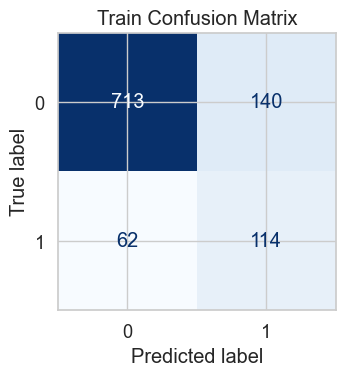

## Test Results

**Accuracy:** 80.73%

### Classification Report

Class / Average,precision,recall,f1-score,support
0,0.909,0.863,0.885,380
1,0.350,0.459,0.397,61
macro avg,0.629,0.661,0.641,441
weighted avg,0.831,0.807,0.818,441


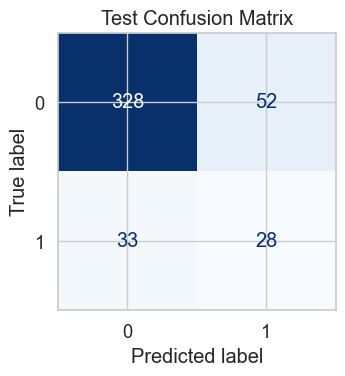

CPU times: user 4.71 s, sys: 984 ms, total: 5.69 s
Wall time: 27.3 s


In [16]:
%%time

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

params = {
    "criterion":("gini", "entropy"), 
    "splitter":("best", "random"), 
    "max_depth":(list(range(1, 20))), 
    "min_samples_split":[2, 3, 4], 
    "min_samples_leaf":list(range(1, 20)),
    "class_weight": [None, "balanced"] # Not present in the original author notebook
}


tree_clf = DecisionTreeClassifier(random_state=random_state)

# GridSearchCV tries every combination of the values you list (a Cartesian product) and keeps the one with the best score:
tree_cv = GridSearchCV(
    tree_clf, 
    params, 
    scoring="f1", 
    n_jobs=-1, 
    verbose=1, 
    cv=5
)

tree_cv.fit(X_train, y_train)
best_params = tree_cv.best_params_
#print(f"Best parameters: {best_params})")

def display_best_params(search):
    """Show a fitted GridSearchCV / RandomizedSearchCV: best CV score and parameters."""
    params_df = pd.DataFrame({
        "Parameter": list(search.best_params_),
        "Value": [str(v) for v in search.best_params_.values()],
    })
    display(Markdown(f"**Best CV {search.scoring}:** {search.best_score_:.3f}"))
    display_table(params_df)

display_best_params(tree_cv)

tree_clf = DecisionTreeClassifier(random_state=random_state, **best_params) # Added the common random seed which is not part of best_params
tree_clf.fit(X_train, y_train)
print_score(tree_clf, X_train, y_train, X_test, y_test, train=True)
print_score(tree_clf, X_train, y_train, X_test, y_test, train=False)

models["Decision Tree + Grid Search"] = tree_clf

### Visualization of a tree

In [17]:
from IPython.display import Image
from six import StringIO
from sklearn.tree import export_graphviz
import pydot

features = list(df.columns)
features.remove("Attrition")

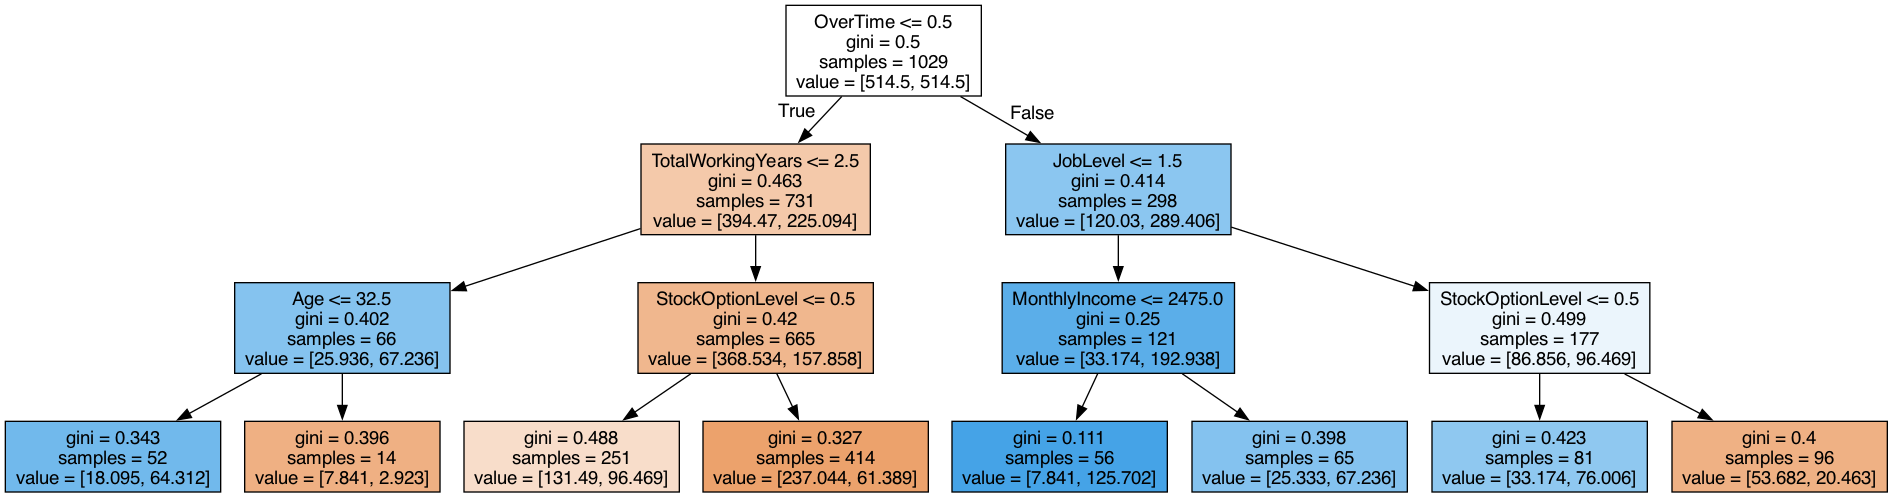

In [18]:
dot_data = StringIO()
export_graphviz(tree_clf, out_file=dot_data, feature_names=features, filled=True)
graph = pydot.graph_from_dot_data(dot_data.getvalue())
Image(graph[0].create_png())

# 3. Random Forest

A random forest is a meta estimator that fits a number of decision tree classifiers on various sub-samples of the dataset and uses averaging to improve the predictive accuracy and control over-fitting.

- **Random forest algorithm parameters:**
- `n_estimators`: The number of trees in the forest.
*** 
- `criterion`: The function to measure the quality of a split. Supported criteria are "`gini`" for the Gini impurity and "`entropy`" for the information gain.
***
- `max_depth`: The maximum depth of the tree. If None, then nodes are expanded until all leaves are pure or until all leaves contain less than `min_samples_split` samples.
***
- `min_samples_split`: The minimum number of samples required to split an internal node.
***
- `min_samples_leaf`: The minimum number of samples required to be at a leaf node. A split point at any depth will only be considered if it leaves at least ``min_samples_leaf`` training samples in each of the left and right branches.  This may have the effect of smoothing the model, especially in regression.
***
- `min_weight_fraction_leaf`: The minimum weighted fraction of the sum total of weights (of all the input samples) required to be at a leaf node. Samples have equal weight when sample_weight is not provided.
***
- `max_features`: The number of features to consider when looking for the best split.
***
- `max_leaf_nodes`: Grow a tree with ``max_leaf_nodes`` in best-first fashion. Best nodes are defined as relative reduction in impurity. If None then unlimited number of leaf nodes.
***
- `min_impurity_decrease`: A node will be split if this split induces a decrease of the impurity greater than or equal to this value.
***
- `min_impurity_split`: Threshold for early stopping in tree growth. A node will split if its impurity is above the threshold, otherwise it is a leaf.
***
- `bootstrap`: Whether bootstrap samples are used when building trees. If False, the whole datset is used to build each tree.
***
- `oob_score`: Whether to use out-of-bag samples to estimate the generalization accuracy.

## Train Results

**Accuracy:** 100.00%

### Classification Report

Class / Average,precision,recall,f1-score,support
0,1.000,1.000,1.000,853
1,1.000,1.000,1.000,176
macro avg,1.000,1.000,1.000,"1,029"
weighted avg,1.000,1.000,1.000,"1,029"


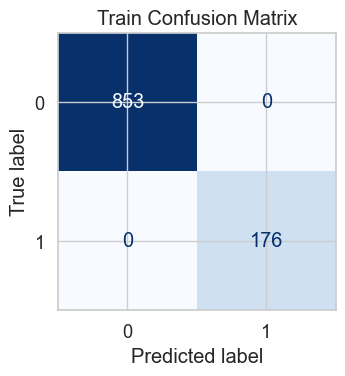

## Test Results

**Accuracy:** 86.39%

### Classification Report

Class / Average,precision,recall,f1-score,support
0,0.872,0.987,0.926,380
1,0.545,0.098,0.167,61
macro avg,0.709,0.543,0.546,441
weighted avg,0.827,0.864,0.821,441


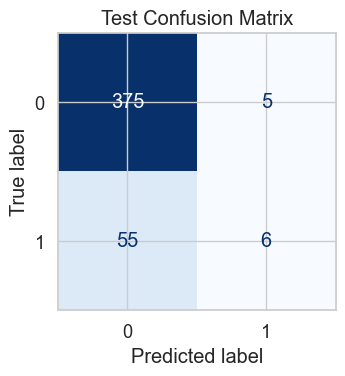

CPU times: user 537 ms, sys: 1.11 s, total: 1.64 s
Wall time: 409 ms


In [19]:
%%time
from sklearn.ensemble import RandomForestClassifier

rf_clf = RandomForestClassifier(n_estimators=100)
rf_clf.fit(X_train, y_train)

print_score(rf_clf, X_train, y_train, X_test, y_test, train=True)
print_score(rf_clf, X_train, y_train, X_test, y_test, train=False)

models["Random Forest"] = rf_clf

## 4. Random Forest hyperparameter tuning

### a) Randomized Search Cross Validation

Reference [RandomizedSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html)

`class sklearn.model_selection.RandomizedSearchCV(estimator, param_distributions, *, n_iter=10, scoring=None, n_jobs=None, refit=True, cv=None, verbose=0, pre_dispatch='2*n_jobs', random_state=None, error_score=nan, return_train_score=False)`

### Replacing the obsolete `max_features="auto"`

Older examples use `max_features="auto"` for `RandomForestClassifier`. This option was deprecated and is no longer accepted by current versions. Candidates containing it fail during cross-validation and receive `NaN` scores. Update the parameter lists in both randomized and grid searches rather than suppressing the resulting warnings.

For this classifier, the old `"auto"` behavior is equivalent to `"sqrt"`. `max_features` controls the number of randomly selected features considered at each split.

| Alternative | Meaning |
| --- | --- |
| `"sqrt"` | Square root of the feature count, rounded down with a minimum of one. Preserves the old classifier behavior. |
| `"log2"` | Base-2 logarithm of the feature count, rounded down with a minimum of one. |
| `None` | Consider all features. |
| Integer, e.g. `5` | Specify a feature count directly. |
| Float, e.g. `0.5` | Specify a fraction of the features, rounded down with a minimum of one. |

For example, with 30 input features, `"sqrt"` selects 5 features per split and `"log2"` selects 4. The splitter may inspect additional features if necessary to find a valid partition.

Use one of these search configurations:

```python
# Preserve the old "auto" behavior; tune the other parameters only.
max_features = ["sqrt"]

# Alternatively, let cross-validation compare two strategies.
max_features = ["sqrt", "log2"]
```

Use the chosen list as the value of `"max_features"` in the search dictionary. A two-option list expands the choices available to the search; it does not apply both strategies at once to a single model. With a fixed `n_iter`, randomized search still samples that many candidates (subject to the available combinations).

The `"auto"` → `"sqrt"` equivalence here applies specifically to **RandomForestClassifier**.

Source: [scikit-learn RandomForestClassifier documentation](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html).

Fitting 5 folds for each of 200 candidates, totalling 1000 fits


**Best CV f1:** 0.527

Parameter,Value
n_estimators,200
min_samples_split,10
min_samples_leaf,4
max_features,log2
max_depth,10
class_weight,balanced
bootstrap,False


## Train Results

**Accuracy:** 98.45%

### Classification Report

Class / Average,precision,recall,f1-score,support
0,1.000,0.981,0.991,853
1,0.917,1.000,0.957,176
macro avg,0.958,0.991,0.974,"1,029"
weighted avg,0.986,0.984,0.985,"1,029"


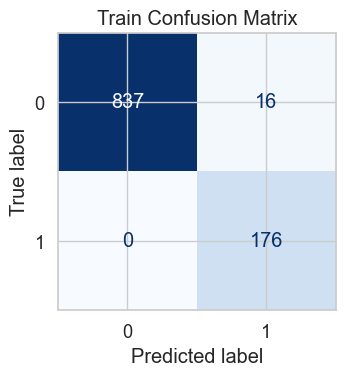

## Test Results

**Accuracy:** 85.03%

### Classification Report

Class / Average,precision,recall,f1-score,support
0,0.896,0.934,0.915,380
1,0.444,0.328,0.377,61
macro avg,0.670,0.631,0.646,441
weighted avg,0.834,0.850,0.841,441


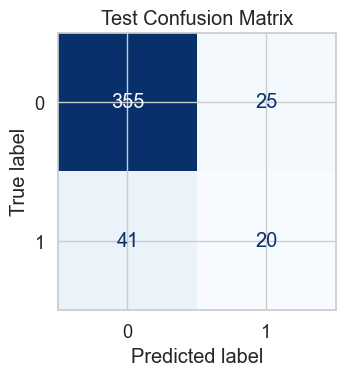

CPU times: user 2.48 s, sys: 443 ms, total: 2.92 s
Wall time: 2min 12s


In [20]:
%%time

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV

n_estimators = [int(x) for x in np.linspace(start=200, stop=2000, num=10)]
max_features =  ["sqrt", "log2"] # Deprecated: max_features = ['auto', 'sqrt']
#max_features =  ["sqrt"] # Deprecated: max_features = ['auto', 'sqrt']
max_depth = [int(x) for x in np.linspace(10, 110, num=11)]
max_depth.append(None)
min_samples_split = [2, 5, 10]
min_samples_leaf = [1, 2, 4]
bootstrap = [True, False]

random_grid = {
    'n_estimators': n_estimators,
    'max_features': max_features,
    'max_depth': max_depth,
    'min_samples_split': min_samples_split,
    'min_samples_leaf': min_samples_leaf,
    'bootstrap': bootstrap,
    "class_weight": [None, "balanced"] # Not present in the original author notebook
}

rf_clf = RandomForestClassifier(random_state=random_state)

rf_cv = RandomizedSearchCV(
    estimator=rf_clf,
    scoring='f1',
    param_distributions=random_grid,
    n_iter=200,
    cv=5,
    verbose=1,
    random_state=random_state,
    n_jobs=-1, # -1 means using all processors.
    error_score="raise", # stop immediately on future fitting errors
)

rf_cv.fit(X_train, y_train)
rf_best_params = rf_cv.best_params_
#print(f"Best parameters: {rf_best_params})")
display_best_params(rf_cv)

rf_clf = RandomForestClassifier(random_state=random_state, **rf_best_params) # Added the common random seed which is not part of best_params
rf_clf.fit(X_train, y_train)

print_score(rf_clf, X_train, y_train, X_test, y_test, train=True)
print_score(rf_clf, X_train, y_train, X_test, y_test, train=False)

models["Random Forest + Randomized Search"] = rf_clf

`Random search` allowed us to narrow down the range for each hyperparameter. Now that we know where to concentrate our search, we can explicitly specify every combination of settings to try. We do this with `GridSearchCV`, a method that, instead of sampling randomly from a distribution, evaluates all combinations we define.

### b) Grid Search Cross Validation

Reference: [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)

`class sklearn.model_selection.GridSearchCV(estimator, param_grid, *, scoring=None, n_jobs=None, refit=True, cv=None, verbose=0, pre_dispatch='2*n_jobs', error_score=nan, return_train_score=False)`

Fitting 5 folds for each of 1536 candidates, totalling 7680 fits


**Best CV f1:** 0.537

Parameter,Value
bootstrap,False
class_weight,balanced
max_depth,None
max_features,log2
min_samples_leaf,10
min_samples_split,2
n_estimators,500


## Train Results

**Accuracy:** 93.88%

### Classification Report

Class / Average,precision,recall,f1-score,support
0,1.000,0.926,0.962,853
1,0.736,1.000,0.848,176
macro avg,0.868,0.963,0.905,"1,029"
weighted avg,0.955,0.939,0.942,"1,029"


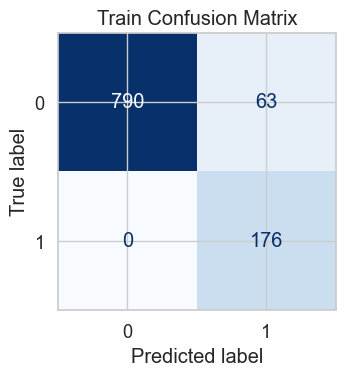

## Test Results

**Accuracy:** 81.41%

### Classification Report

Class / Average,precision,recall,f1-score,support
0,0.907,0.874,0.890,380
1,0.360,0.443,0.397,61
macro avg,0.634,0.658,0.644,441
weighted avg,0.831,0.814,0.822,441


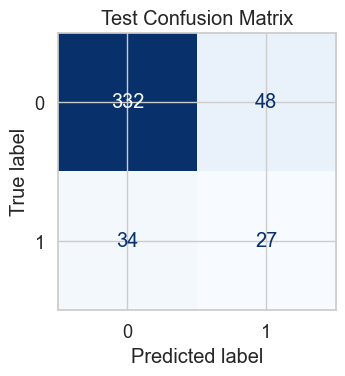

CPU times: user 11.6 s, sys: 2.06 s, total: 13.6 s
Wall time: 9min 15s


In [21]:
%%time

n_estimators = [100, 500, 1000, 1500]
max_features =  ["sqrt", "log2"] # Deprecated: max_features = ['auto', 'sqrt']
#max_features =  ["sqrt"] # Deprecated: max_features = ['auto', 'sqrt']
max_depth = [2, 3, 5]
max_depth.append(None)
min_samples_split = [2, 5, 10]
min_samples_leaf = [1, 2, 4, 10]
bootstrap = [True, False]

params_grid = {
    'n_estimators': n_estimators, 
    'max_features': max_features,
    'max_depth': max_depth, 
    'min_samples_split': min_samples_split,
    'min_samples_leaf': min_samples_leaf, 
    'bootstrap': bootstrap,
    "class_weight": [None, "balanced"] # Not present in the original author notebook
}

rf_clf = RandomForestClassifier(random_state=random_state)

rf_cv = GridSearchCV(
    rf_clf, 
    params_grid, 
    scoring="f1", 
    cv=5, 
    verbose=1, 
    n_jobs=-1, # -1 means using all processors.
    error_score="raise", # stop immediately on future fitting errors
)


rf_cv.fit(X_train, y_train)
best_params = rf_cv.best_params_
#print(f"Best parameters: {best_params}")
display_best_params(rf_cv)

rf_clf = RandomForestClassifier(random_state=random_state, **best_params) # Added the common random seed which is not part of best_params
rf_clf.fit(X_train, y_train)

print_score(rf_clf, X_train, y_train, X_test, y_test, train=True)
print_score(rf_clf, X_train, y_train, X_test, y_test, train=False)

models["Random Forest + Grid Search"] = rf_clf

In [22]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

rows = []
for name, model in models.items():
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    rows.append({
        "Model": name,
        "Train F1": f1_score(y_train, train_pred),
        "Test F1": f1_score(y_test, test_pred),
        "Test precision": precision_score(y_test, test_pred, zero_division=0),
        "Test recall": recall_score(y_test, test_pred),
        "Test accuracy": accuracy_score(y_test, test_pred),
    })

summary_df = pd.DataFrame(rows)
metric_cols = [c for c in summary_df.columns if c != "Model"]

display(Markdown("## Model comparison (positive class: Attrition = 1)"))
display_table(
    summary_df,
    formats={c: "{:.3f}" for c in metric_cols},
    html_style=gradient_html,
    latex_style=gradient_latex,
    style_columns=metric_cols,
    fit_to_page=True,
)

# Optional: show each model's configuration
for name, model in models.items():
    display(Markdown(f"**{name}**"))
    display_estimator(model)

## Model comparison (positive class: Attrition = 1)

Model,Train F1,Test F1,Test precision,Test recall,Test accuracy
Decision Tree,1.000,0.290,0.260,0.328,0.778
Decision Tree + Grid Search,0.530,0.397,0.350,0.459,0.807
Random Forest,1.000,0.167,0.545,0.098,0.864
Random Forest + Randomized Search,0.957,0.377,0.444,0.328,0.850
Random Forest + Grid Search,0.848,0.397,0.360,0.443,0.814


**Decision Tree**

DecisionTreeClassifier(random_state=42)

**Decision Tree + Grid Search**

DecisionTreeClassifier(class_weight='balanced', max_depth=3,
                       min_samples_leaf=11, random_state=42)

... (2 outputs left out)

**Random Forest + Randomized Search**

RandomForestClassifier(bootstrap=False, class_weight='balanced', max_depth=10,
                       max_features='log2', min_samples_leaf=4,
                       min_samples_split=10, n_estimators=200, random_state=42)

**Random Forest + Grid Search**

RandomForestClassifier(bootstrap=False, class_weight='balanced',
                       max_features='log2', min_samples_leaf=10,
                       n_estimators=500, random_state=42)

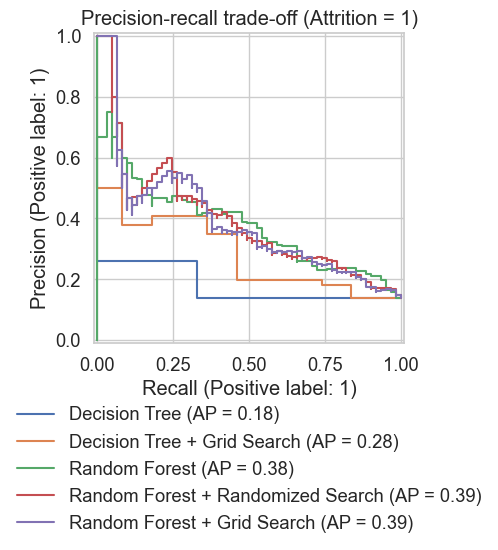

In [23]:
from sklearn.metrics import PrecisionRecallDisplay

fig, ax = plt.subplots(figsize=(7, 6))
for name, model in models.items():
    PrecisionRecallDisplay.from_estimator(model, X_test, y_test, name=name, ax=ax)

ax.set_title("Precision-recall trade-off (Attrition = 1)")
ax.legend(
    loc="upper center",            # the legend's anchor point is its top-centre...
    bbox_to_anchor=(0.5, -0.15),   # ...placed centred, just below the x-axis
    ncol=1,
    frameon=False,
)
fig.tight_layout()
plt.show()

## Conclusions

### 1. Results without class weights

| Model | Train F1 | Test F1 | Test precision | Test recall | Test accuracy |
|---|---|---|---|---|---|
| Decision Tree | 1.000 | 0.290 | 0.260 | 0.328 | 0.778 |
| Decision Tree + Grid Search | 0.475 | 0.310 | 0.565 | 0.213 | 0.868 |
| Random Forest | 1.000 | 0.145 | 0.625 | 0.082 | 0.866 |
| Random Forest + Randomized Search | 0.971 | 0.141 | 0.500 | 0.082 | 0.862 |
| Random Forest + Grid Search | 1.000 | 0.192 | 0.583 | 0.115 | 0.866 |

At first glance accuracy looks good (about 0.86), but it's misleading. The test set has **380 employees who stay and 61 who leave**, so a model that always predicts "No" scores **380 / 441 = 0.862** without learning anything. The models are close to doing exactly that: the random forests catch only **5 of the 61** leavers (recall 0.082). Most models also overfit heavily (train F1 = 1.000).

### 2. Results with class weights

`class_weight="balanced"` for the decision trees and `class_weight="balanced_subsample"` for the random forests make errors on the minority class ("Yes") count more during training.

| Model | Train F1 | Test F1 | Test precision | Test recall | Test accuracy |
|---|---|---|---|---|---|
| Decision Tree | 1.000 | 0.290 | 0.260 | 0.328 | 0.778 |
| Decision Tree + Grid Search | 0.530 | **0.397** | 0.350 | **0.459** | 0.807 |
| Random Forest | 1.000 | 0.164 | 0.500 | 0.098 | 0.862 |
| Random Forest + Randomized Search | 0.957 | 0.377 | 0.444 | 0.328 | 0.850 |
| Random Forest + Grid Search | 0.848 | **0.397** | 0.360 | 0.443 | 0.814 |

### 3. Change after adding class weights (weighted − unweighted)

| Model | Train F1 | Test F1 | Test precision | Test recall | Test accuracy |
|---|---|---|---|---|---|
| Decision Tree | 0.000 | 0.000 | 0.000 | 0.000 | 0.000 |
| Decision Tree + Grid Search | +0.055 | **+0.087** | −0.215 | **+0.246** | −0.061 |
| Random Forest | 0.000 | +0.019 | −0.125 | +0.016 | −0.004 |
| Random Forest + Randomized Search | −0.014 | **+0.236** | −0.056 | **+0.246** | −0.012 |
| Random Forest + Grid Search | −0.152 | **+0.205** | −0.223 | **+0.328** | −0.052 |

- **Every tuned model improved its F1 and recall**, at the cost of precision and accuracy.
- **The untuned models barely changed.** Fully grown trees end in pure leaves, so class weights have almost nothing to act on. Weights only make a difference when tree growth is limited (`max_depth`, `min_samples_leaf`), which is what the tuned models do.
- **Overfitting decreased** for the forest grid search: the train F1 went from 1.000 to 0.848, closer to its test F1.

### 4. The trade-off in numbers

The percentages are easier to judge as employee counts (61 actual leavers in the test set):

| | Tree + Grid Search: unweighted | Tree + Grid Search: weighted | Forest + Grid Search: unweighted | Forest + Grid Search: weighted |
|---|---|---|---|---|
| Leavers caught | 13 | **28** | 7 | **27** |
| Leavers missed | 48 | **33** | 54 | **34** |
| Employees flagged as "Yes" | 23 | 80 | 12 | 75 |
| False alarms | 10 | 52 | 5 | 48 |

With the weighted tree, HR would identify **15 more leavers** at the cost of **42 more false alarms**. Precision and accuracy drop because the model now says "Yes" much more often. They don't drop because the model got worse at separating the classes.

### 5. Which metric should we use?

Our objective is to **identify employees at risk of leaving** so that HR can step in. A missed leaver (a false negative) means losing an employee plus the cost of hiring and training a replacement. A false alarm (a false positive) usually costs a conversation with an employee who wasn't going to leave. Missed leavers are more expensive, so:

- **Accuracy: don't use it.** It rewards predicting "No" for everyone (0.862 with zero leavers caught).
- **Recall: the metric we care about most**, but not on its own. A model that flags everyone gets recall = 1.0 and is useless.
- **F1: a reasonable metric for tuning.** It balances precision and recall, and it's what our searches optimised. If missing leavers is clearly worse than false alarms, **F2** (`make_scorer(fbeta_score, beta=2)`) weights recall more heavily and fits this objective better.
- **Average precision (area under the precision-recall curve): for comparing models.** It doesn't depend on the 0.5 threshold, so it judges how well each model ranks employees by risk. We can then choose the threshold separately, based on how many false alarms HR can handle.

### 6. Final choice and limitations

The weighted **Decision Tree + Grid Search** and **Random Forest + Grid Search** tie on test F1 (0.397), and the tree has slightly higher recall (0.459 vs 0.443). With only 61 positive cases, each leaver changes recall by about 1.6 points, so the two are effectively **equivalent**. In that case we prefer the **decision tree**: it's faster to train and can be fully visualised and explained to HR.

Even so, an F1 of about 0.40 is modest. The dataset is small (about 1,000 training rows) and imbalanced, and the original notebook didn't account for the imbalance. Possible next steps: a stratified train/test split, choosing the decision threshold with cross-validation, and a `LogisticRegression(class_weight="balanced")` baseline, which often performs well on this dataset.

# Summary
In this notebook we learned the following lessons:
- Decsion tree and random forest algorithms and the parameters of each algorithm.
- How to tune hyperparameters for both Decision tree and Random Forest.
- Balance your dataset before training to prevent the tree from being biased toward the classes that are dominant. 
  - By sampling an equal number of samples from each class  
  - By normalizing the sum of the sample weights (sample_weight) for each class to the same value. 

  
## References:
- [Hyperparameter Tuning the Random Forest in Python](https://towardsdatascience.com/hyperparameter-tuning-the-random-forest-in-python-using-scikit-learn-28d2aa77dd74)
- [Decision Trees](https://scikit-learn.org/stable/modules/tree.html)
- [Ensemble methods](https://scikit-learn.org/stable/modules/ensemble.html#forests-of-randomized-trees)
- [Bagging and Random Forest Ensemble Algorithms for Machine Learning](https://machinelearningmastery.com/bagging-and-random-forest-ensemble-algorithms-for-machine-learning/)